# Resumen de pruebas para KLEIN (4x4)

Este notebook carga la S-Box `data/clasics/KLEIN.json`, construye y muestra la DDT,
y calcula metricas criptograficas y de cadena de Markov.

In [8]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sboxes.loader import load as load_sbox
from evaluation.uniformity import get_ddt
from evaluation.fixed_points import fixed_ponts
from evaluation.linearity import evaluate
from evaluation.avalanche_criterion import avalanche_criterion
from evaluation.markov_chains.basic_markov_chain import (
    DifferentialMarkovChain,
    create_transition_matrix,
)

In [9]:
sbox_path = "data/clasics/S-BOX_SPN4.json"
sbox = load_sbox(sbox_path)
table_hex = [hex(int(v)) for v in sbox.table]

print(f"Nombre: {sbox.name}")
print(f"Dimension: {sbox.input_size}x{sbox.output_size}")
print(f"Tabla ({len(table_hex)} entradas): {table_hex}")

pd.DataFrame({"x": list(range(len(table_hex))), "S(x)": table_hex})

Nombre: SPN-4bits
Dimension: 4x4
Tabla (16 entradas): ['0xe', '0x4', '0xd', '0x1', '0x2', '0xf', '0xb', '0x8', '0x3', '0xa', '0x6', '0xc', '0x5', '0x9', '0x0', '0x7']


,x,S(x)
0,0,0xe
1,1,0x4
2,2,0xd
3,3,0x1
4,4,0x2
5,5,0xf
6,6,0xb
7,7,0x8
8,8,0x3
9,9,0xa


In [10]:
ddt = get_ddt(sbox)
ddt_df = pd.DataFrame(
    ddt,
    index=[f"dx={i}" for i in range(ddt.shape[0])],
    columns=[f"dy={j}" for j in range(ddt.shape[1])],
)
ddt_df

,dy=0,dy=1,dy=2,dy=3,dy=4,dy=5,dy=6,dy=7,dy=8,dy=9,dy=10,dy=11,dy=12,dy=13,dy=14,dy=15
dx=0,16,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
dx=1,0,0,0,2,0,0,0,2,0,2,4,0,4,2,0,0
dx=2,0,0,0,2,0,6,2,2,0,2,0,0,0,0,2,0
dx=3,0,0,2,0,2,0,0,0,0,4,2,0,2,0,0,4
dx=4,0,0,0,2,0,0,6,0,0,2,0,4,2,0,0,0
dx=5,0,4,0,0,0,2,2,0,0,0,4,0,2,0,0,2
dx=6,0,0,0,4,0,4,0,0,0,0,0,0,2,2,2,2
dx=7,0,0,2,2,2,0,2,0,0,2,2,0,0,0,0,4
dx=8,0,0,0,0,0,0,2,2,0,0,0,4,0,4,2,2
dx=9,0,2,0,0,2,0,0,4,2,0,2,2,2,0,0,0


In [11]:
ddt_df.to_csv("ddtAES.csv")

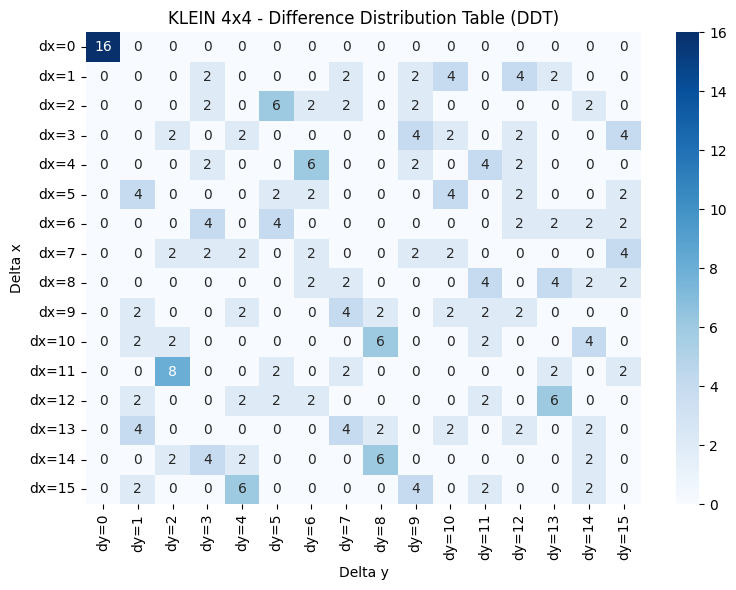

In [12]:
plt.figure(figsize=(8, 6))
sns.heatmap(ddt_df, annot=True, fmt="d", cmap="Blues", cbar=True)
plt.title("KLEIN 4x4 - Difference Distribution Table (DDT)")
plt.xlabel("Delta y")
plt.ylabel("Delta x")
plt.tight_layout()
plt.show()

In [13]:
avg_sac, sac_per_input, std_per_input, max_std = avalanche_criterion(sbox)
fixed_points = int(fixed_ponts(sbox, detail=True)[1])
max_ddt = int(ddt.max())
uniformity = int(ddt[1:].max()) if ddt.shape[0] > 1 else max_ddt

transition_matrix = create_transition_matrix(
    np.asarray(sbox.table, dtype=np.int64),
    int(sbox.input_size),
    int(sbox.output_size),
    skip_zero=True,
)
chain = DifferentialMarkovChain(transition_matrix)

metrics_df = pd.DataFrame([
    {
        "name": sbox.name,
        "input_size": int(sbox.input_size),
        "output_size": int(sbox.output_size),
        "uniformity": uniformity,
        "max_ddt": max_ddt,
        "fixed_points": fixed_points,
        "non_linearity": float(evaluate(sbox)),
        "avg_sac": float(avg_sac),
        "max_std_sac": float(max_std),
        "sac_per_input": [float(x) for x in np.round(sac_per_input, 6)],
        "std_sac_per_input": [float(x) for x in np.round(std_per_input, 6)],
        "spectral_gap": float(chain.spectral_gap()),
        "tv_distance_r4": float(chain.tv_distance(4)),
        "max_probability_r4": float(chain.max_probability(4)),
        "mixing_time_eps_1e-3": int(chain.mixing_time_iterative(epsilon=1e-3, max_steps=10_000)),
        "mixing_time_spectral_eps_1e-3": float(chain.mixing_time_spectral(eps=1e-3)),
    }
])

metrics_df

,name,input_size,output_size,uniformity,max_ddt,fixed_points,non_linearity,avg_sac,max_std_sac,sac_per_input,std_sac_per_input,spectral_gap,tv_distance_r4,max_probability_r4,mixing_time_eps_1e-3,mixing_time_spectral_eps_1e-3
0,SPN-4bits,4,4,8,16,0,2.0,0.609375,0.207289,"[0.5625, 0.5625, 0.5625, 0.75]","[0.108253, 0.207289, 0.108253, 0.0]",0.603789,0.045785,0.082031,9,11.0


In [14]:
metrics_df.to_csv("klein_metrics_summary.csv", index=False)
ddt_df.to_csv("klein_ddt.csv", index=True)
print("Guardado: klein_metrics_summary.csv")
print("Guardado: klein_ddt.csv")

Guardado: klein_metrics_summary.csv
Guardado: klein_ddt.csv
